# Lattice construction

In [2]:
lattice_name   = 'v01_04_01_01'
description    = 'LGB lattice starting from v01_03_01_01 with higher MCF.'
finalized_date = '261116'

In [3]:
# Standard imports
import numpy as np
import scipy
import matplotlib.pyplot as plt

import pickle
import os
from copy import deepcopy

import at

import utils as u

from importlib import reload

reload(u.at);
reload(u.plot);

## Load ring

In [4]:
with open('candidates/v01_03_01_01/ring.pkl', 'rb') as file:
    ring0 = pickle.load(file)

with open('candidates/n01_02_01_01/ring.pkl', 'rb') as file:
    TDR_1 = pickle.load(file)

ring = deepcopy(ring0)

## Free-form optimization

In [5]:
from IPython.display import clear_output
def callback(intermediate_result):
    clear_output(wait=True)
    print('Running...')
    print(intermediate_result)

def set_x(ring, x, index_rho, index_K):
    # Unpack
    L = x[0]
    rho_inv = x[1:len(index_rho)+1]
    K = x[len(index_rho)+1:]

    assert len(rho_inv) == len(index_rho), f"rho_inv and index_rho should have the same lengths but have lengths {len(rho_inv)} and {len(index_rho)}"
    assert len(K) == len(index_K), f"rho_inv and index_rho should have the same lengths but have lengths {len(K)} and {len(index_K)}"

    for e in ring['strx203']: e.Length = L
    for i, e in enumerate(ring[index_rho]): e.BendingAngle = e.Length * rho_inv[i]
    for i, e in enumerate(ring[index_K]): e.K = K[i]

def get_x(ring, index_rho, index_K):
    L = ring['strx203'][0].Length

    rho_inv = [ring[i].BendingAngle/ring[i].Length for i in index_rho]
    K       = [ring[i].K                           for i in index_K]

    return np.array([L] + rho_inv + K)

def loss(x, ring, index_rho, index_K):
    # Set fields
    set_x(ring, x, index_rho, index_K)

    try:
        emittance = 1e12 * ring.radiation_parameters().emittances[0]
    except Exception as e:
        emittance = 1000

    return emittance

def exact_constraints(x, ring, index_rho, index_K):
    # Set fields
    set_x(ring, x, index_rho, index_K)

    """ Geometric constraints """
    geometry = ring.get_geometry(at.End)[0]
    geometry0 = ring0.get_geometry(at.End)[0]

    x_end = geometry.x[0] - geometry0.x[0]
    theta_UC = geometry.angle[0] - geometry0.angle[0]

    """ Optics """
    elemdata = at.linopt4(ring, at.All)[2]

    # Dispersion
    D0, Dp0 = elemdata.dispersion[0, 0:2]

    return x_end, theta_UC, D0, Dp0

def phase_constraints(x, ring, index_rho, index_K):
    tune = np.array([58.399, 17.168])
    UC_tune = np.array([0.4, 0.1])

    # Set fields
    set_x(ring, x, index_rho, index_K)

    """ Optics """
    elemdata = at.linopt4(ring, at.All)[2]

    # Unit cell phase advance
    index_UC = ring.get_uint32_index('UCborder')
    phase_diff = (np.diff(elemdata.mu[index_UC], axis=0)/(2*np.pi) - UC_tune).flatten()

    # Full tunes
    tune_diff = 20*elemdata.mu[-1]/(2*np.pi) - tune

    return 1e-3 + np.hstack([-phase_diff, phase_diff, -tune_diff, tune_diff]) # Within 1-e3 

def mcf_constraints(x, ring, index_rho, index_K):
    # Set fields
    set_x(ring, x, index_rho, index_K)

    return ring.get_mcf() - 5e-5

n_D1 = len(ring['D1_v1'])//2
n_D2 = len(ring['D2_v1'])//10
n_R1 = len(ring['R1_v1'])//10 # Should be 1

index_rho = np.hstack([ring.uint32_refpts('D1_v1')[:n_D1],
                       ring.uint32_refpts('R1_v1')[:n_R1],
                       ring.uint32_refpts('D2_v1')[:n_D2]])

index_K = np.hstack([ring.uint32_refpts('Q1_v1')[0],
                     ring.uint32_refpts('Q2_v1')[0],
                     ring.uint32_refpts('D1_v1')[:n_D1],
                     ring.uint32_refpts('Q3_v1')[0],
                     ring.uint32_refpts('R1_v1')[:n_R1],
                     ring.uint32_refpts('D2_v1')[:n_D2]])

In [6]:
bounds = (1 + len(index_rho) + len(index_K))*[(None, None)]
for i, index in enumerate(index_rho, 1):
    FamName = ring[index].FamName

    if 'D1' in FamName or 'D2' in FamName: 
        bounds[i] = (0, 0.07)
    if 'R1' in FamName or 'R2' in FamName: 
        bounds[i] = (-0.025, 0)

for i, index in enumerate(index_K, len(index_rho)+1):
    FamName = ring[index].FamName

    if 'D1' in FamName or 'D2' in FamName: 
        bounds[i] = (-1.2, 0)

    if 'R1' in FamName or 'R2' in FamName: 
        bounds[i] = (-6, 6)
    if 'Q1' in FamName or 'Q2' in FamName or 'Q3' in FamName: 
        bounds[i] = (-6, 6)

ring_opt = deepcopy(ring)
result = scipy.optimize.minimize(
    loss,
    get_x(ring_opt, index_rho, index_K),
    args=(ring_opt, index_rho, index_K),
    constraints=[
        {'type':   'eq', 'fun': exact_constraints, 'args': (ring_opt, index_rho, index_K)},
        {'type': 'ineq', 'fun': phase_constraints, 'args': (ring_opt, index_rho, index_K)},
        {'type': 'ineq', 'fun': mcf_constraints,   'args': (ring_opt, index_rho, index_K)},
    ],
    bounds=bounds,
    callback=callback,
)
result

Running...
 fun: 55.97380160503659
   x: [ 2.041e-01  2.616e-10 ... -5.502e-01 -4.065e-01]


     message: Positive directional derivative for linesearch
     success: False
      status: 8
         fun: 55.97380160503659
           x: [ 2.041e-01  2.616e-10 ... -5.502e-01 -4.065e-01]
         nit: 61
         jac: [-4.703e+01  1.879e+02 ...  4.989e-01  5.324e-01]
        nfev: 2890
        njev: 57
 multipliers: [ 3.153e+00 -4.350e+02 ...  0.000e+00  3.776e+05]

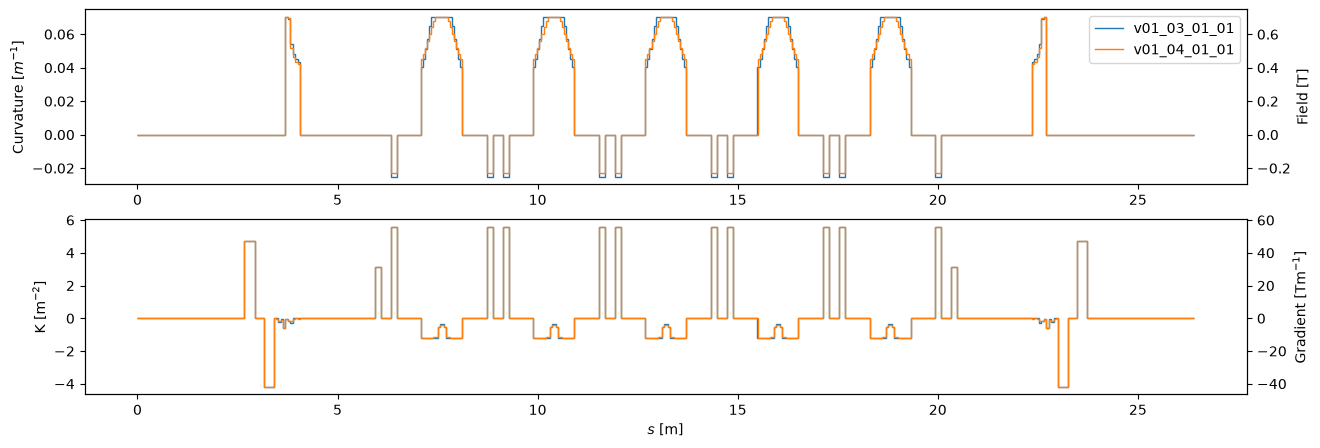

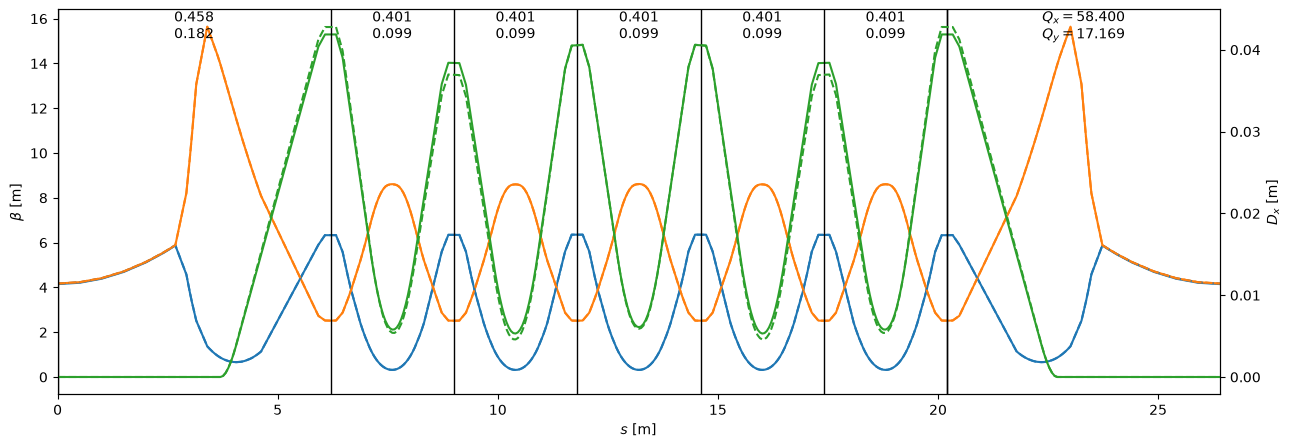

Emittance                  : 56.0 pm.rad
Tunes                      : [58.400, 17.169]
Momentum compaction        : 4.99e-05 d +3.80e-04 d^2 -6.38e-04 d^3
D1 angle                   : 1.119 degrees
Crotch absorber separation : 27.64 mm


In [8]:
fig, axs = plt.subplots(2, 1, figsize=(15, 5))
u.plot.plot_magnet(ring0, axs)
u.plot.plot_magnet(ring_opt, axs)
axs[0].legend(['v01_03_01_01', lattice_name])

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
u.plot.linear(ring_opt, ring0, ax=ax)
plt.show()

reload(u.at)
u.at.summary(ring_opt)

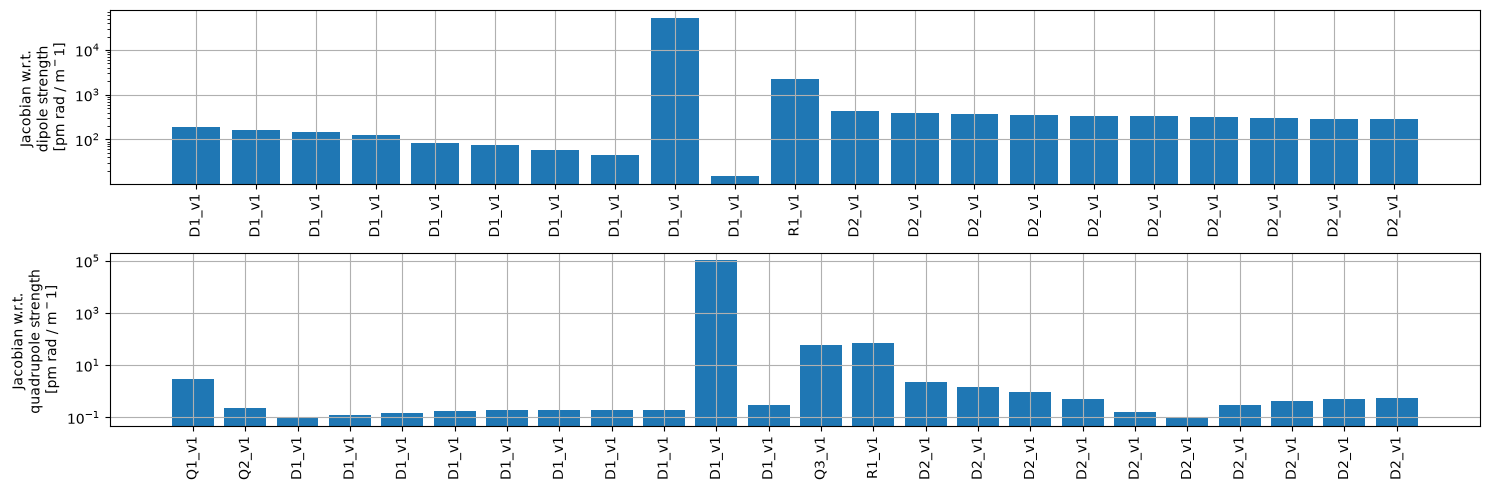

In [9]:
fig, axs = plt.subplots(2, 1, figsize=(15, 5))

axs[0].bar(range(len(index_rho)), abs(result.jac[1:len(index_rho)+1]))
axs[0].set_xticks(range(len(index_rho)), [e.FamName for e in ring[index_rho]], rotation=90)
axs[0].set_ylabel('Jacobian w.r.t. \ndipole strength \n[pm rad / m$^-1$]')
axs[0].set_yscale('log')
axs[0].grid()

axs[1].bar(range(len(index_K)), abs(result.jac[len(index_rho)+1:]))
axs[1].set_xticks(range(len(index_K)), [e.FamName for e in ring[index_K]], rotation=90)
axs[1].set_ylabel('Jacobian w.r.t. \nquadrupole strength \n[pm rad / m$^-1$]')
axs[1].set_yscale('log')
axs[1].grid()

plt.tight_layout()
plt.show()

## Save lattice

In [10]:
try:
    os.mkdir(f'candidates/{lattice_name}')
except FileExistsError:
    pass
    
with open(f'candidates/{lattice_name}/ring.pkl', 'wb') as file:
    pickle.dump(ring_opt, file)

at.save_mat(ring_opt, f'candidates/{lattice_name}/achro.mat')